Total objects in saved catalogue: 1664
Objects usable for BPT: 1664

Usable BPT objects by population:
population
Missed catalogue PN         97
Recovered catalogue PN     474
Unmatched candidate       1093
dtype: int64


/Users/golta/miniconda3/envs/tf311/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


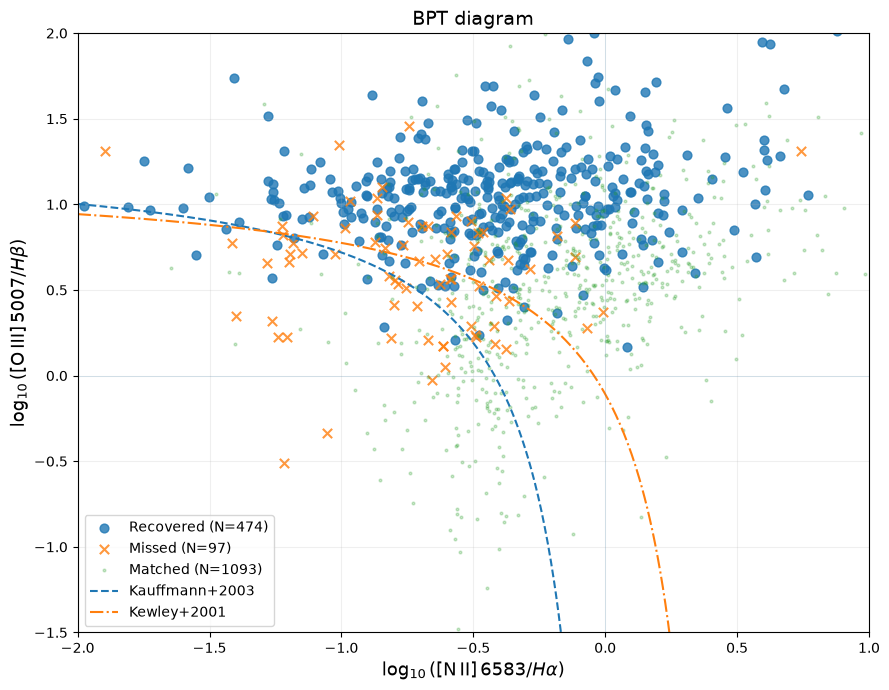

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# BPT DIAGRAM FROM SAVED DIAGNOSTIC CATALOGUE ONLY
# ============================================================

CATALOG_PATH = Path("/Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v4.3/diagnostic_source_measurements_v4.2.csv")

BPT_SNR_MIN = 2.0

df = pd.read_csv(CATALOG_PATH)

# ------------------------------------------------------------
# Require valid, positive fluxes and S/N > 2 in all four lines
# ------------------------------------------------------------
valid_bpt = (
    np.isfinite(df["hb_flux"])
    & np.isfinite(df["oiii_flux"])
    & np.isfinite(df["ha_flux"])
    & np.isfinite(df["nii_flux"])
)

bpt = df.loc[valid_bpt].copy()

# ------------------------------------------------------------
# Calculate BPT coordinates
# ------------------------------------------------------------
bpt["log_NII_Ha"] = np.log10(
    bpt["nii_flux"] / bpt["ha_flux"]
)

bpt["log_OIII_Hb"] = np.log10(
    bpt["oiii_flux"] / bpt["hb_flux"]
)

print(f"Total objects in saved catalogue: {len(df)}")
print(f"Objects usable for BPT: {len(bpt)}")

print("\nUsable BPT objects by population:")
print(bpt.groupby("population").size())


# ============================================================
# Standard BPT reference curves
# ============================================================

# Kauffmann et al. 2003 empirical SF boundary
x_kauff = np.linspace(-2.0, 0.04, 500)
y_kauff = 0.61 / (x_kauff - 0.05) + 1.30

# Kewley et al. 2001 maximum-starburst boundary
x_kewley = np.linspace(-2.0, 0.46, 500)
y_kewley = 0.61 / (x_kewley - 0.47) + 1.19


# ============================================================
# Plot
# ============================================================

plt.figure(figsize=(9, 7))

population_order = [
    "Recovered catalogue PN",
    "Missed catalogue PN",
    "Unmatched candidate",
]

markers = {
    "Recovered catalogue PN": "o",
    "Missed catalogue PN": "x",
    "Unmatched candidate": ".",
}

sizes = {
    "Recovered catalogue PN": 40,
    "Missed catalogue PN": 45,
    "Unmatched candidate": 15,
}

alphas = {
    "Recovered catalogue PN": 0.8,
    "Missed catalogue PN": 0.8,
    "Unmatched candidate": 0.25,
}
population_lab = {
    "Recovered catalogue PN": "Recovered",
    "Missed catalogue PN": "Missed",
    "Unmatched candidate": "Matched",
}




# Reference curves
plt.plot(
    x_kauff,
    y_kauff,
    "--",
    linewidth=1.5,
    label="Kauffmann+2003",
)

plt.plot(
    x_kewley,
    y_kewley,
    "-.",
    linewidth=1.5,
    label="Kewley+2001",
)


plt.xlabel(
    r"$\log_{10}([\mathrm{N\,II}]\,6583 / H\alpha)$",
    fontsize=13,
)

plt.ylabel(
    r"$\log_{10}([\mathrm{O\,III}]\,5007 / H\beta)$",
    fontsize=13,
)

plt.title(
    f"BPT diagram",
    fontsize=14,
)

plt.xlim(-2.0, 1.0)
plt.ylim(-1.5, 2.0)

plt.axhline(0, linewidth=0.5, alpha=0.2)
plt.axvline(0, linewidth=0.5, alpha=0.2)

plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

OIII map: (1733, 6080)
OIII error: (1733, 6080)


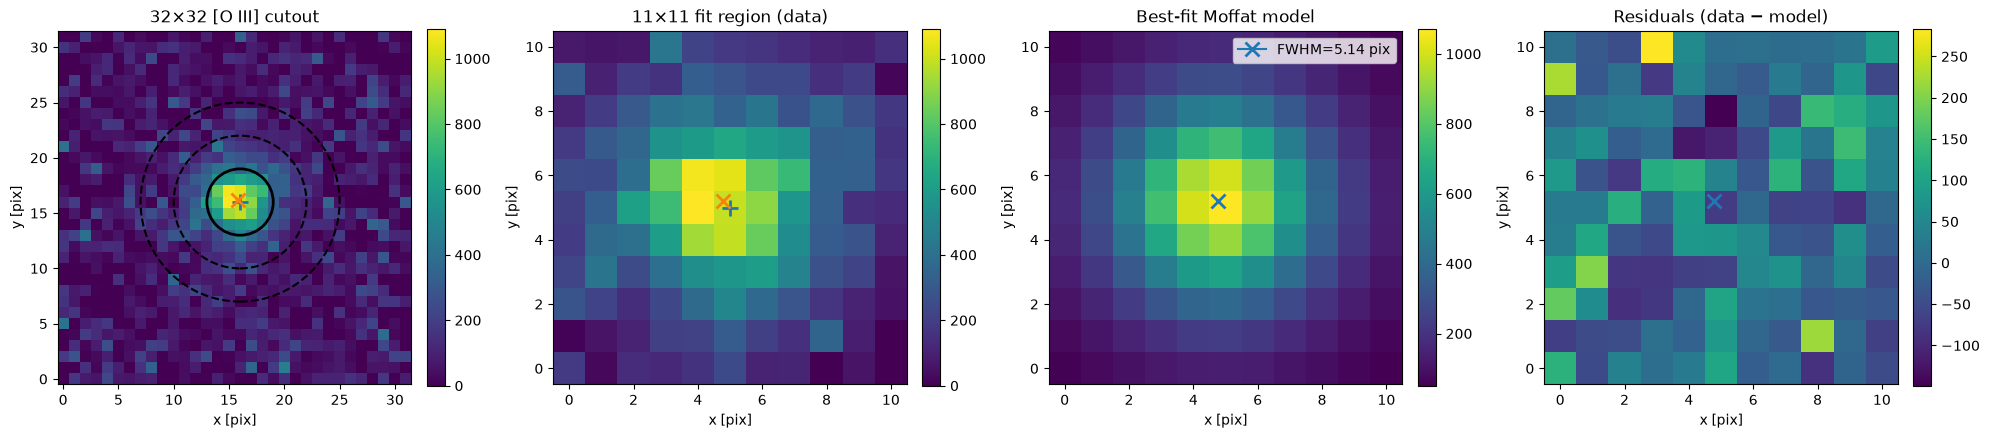

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.optimize import least_squares
from astropy.io import fits

ORIGINAL_FITS_PATH = "/Users/golta/Neb_det/data/ADP.2025-07-06T07_52_11.876.fits"

with fits.open(ORIGINAL_FITS_PATH) as hdul:
    oiii_map = hdul["OIII5006_FLUX"].data.astype(float).copy()
    oiii_err = hdul["OIII5006_FLUX_ERR"].data.astype(float).copy()

print("OIII map:", oiii_map.shape)
print("OIII error:", oiii_err.shape)

# ============================================================
# USER CHOICE: pick one object by row index
# ============================================================
example_index = 0   # change this to any row in your dataframe

# Assumed available:
# df        -> dataframe with source measurements
# oiii_map  -> 2D OIII image
# oiii_err  -> 2D OIII error image

row = df.iloc[example_index]

x0_nom = float(row["center_x"])
y0_nom = float(row["center_y"])

CUTOUT_SIZE = 32
FIT_SIZE = 11
AP_RADIUS = 3.0
ANN_IN = 6.0
ANN_OUT = 9.0
BETA = 2.8


# ============================================================
# Helper functions
# ============================================================
def cutout2d(arr, xc, yc, size):
    half = size // 2
    x0 = int(round(xc)) - half
    x1 = x0 + size
    y0 = int(round(yc)) - half
    y1 = y0 + size
    return arr[y0:y1, x0:x1], x0, y0

def moffat_2d(x, y, A, x0, y0, alpha, B, beta=2.8):
    rr2 = (x - x0)**2 + (y - y0)**2
    return A * (1.0 + rr2 / alpha**2)**(-beta) + B

def fwhm_to_alpha(fwhm, beta=2.8):
    return fwhm / (2.0 * np.sqrt(2.0**(1.0 / beta) - 1.0))

def alpha_to_fwhm(alpha, beta=2.8):
    return 2.0 * alpha * np.sqrt(2.0**(1.0 / beta) - 1.0)

def sigma_clip_median(values, nsig=3.0, maxiters=5):
    vals = np.asarray(values)
    vals = vals[np.isfinite(vals)]
    if len(vals) == 0:
        return np.nan
    for _ in range(maxiters):
        med = np.median(vals)
        std = 1.4826 * np.median(np.abs(vals - med))
        if not np.isfinite(std) or std == 0:
            break
        mask = np.abs(vals - med) < nsig * std
        new_vals = vals[mask]
        if len(new_vals) == len(vals):
            break
        vals = new_vals
        if len(vals) == 0:
            return np.nan
    return np.median(vals) if len(vals) else np.nan


# ============================================================
# Build 32x32 display cutout
# ============================================================
cut32, x32_0, y32_0 = cutout2d(oiii_map, x0_nom, y0_nom, CUTOUT_SIZE)
err32, _, _ = cutout2d(oiii_err, x0_nom, y0_nom, CUTOUT_SIZE)

# coordinates in cutout frame
x_nom_32 = x0_nom - x32_0
y_nom_32 = y0_nom - y32_0

yy32, xx32 = np.indices(cut32.shape)
r32 = np.sqrt((xx32 - x_nom_32)**2 + (yy32 - y_nom_32)**2)

# annulus / aperture masks
ap_mask = r32 <= AP_RADIUS
ann_mask = (r32 >= ANN_IN) & (r32 < ANN_OUT)

bkg_med = sigma_clip_median(cut32[ann_mask])

# ============================================================
# Build 11x11 fitting cutout
# ============================================================
cut11, x11_0, y11_0 = cutout2d(oiii_map, x0_nom, y0_nom, FIT_SIZE)
err11, _, _ = cutout2d(oiii_err, x0_nom, y0_nom, FIT_SIZE)

yy11, xx11 = np.indices(cut11.shape)

# initial guesses
peak_guess = np.nanmax(cut11)
bkg_guess = sigma_clip_median(cut11.ravel())
A_guess = max(peak_guess - bkg_guess, 1e-6)
fwhm_guess = 4.0
alpha_guess = fwhm_to_alpha(fwhm_guess, beta=BETA)

# nominal center in the 11x11 frame
x_nom_11 = x0_nom - x11_0
y_nom_11 = y0_nom - y11_0

# parameter bounds:
# A > 0
# x0,y0 within +-1 pixel
# FWHM between 1 and 10 pix
# B free
lower = [0.0, x_nom_11 - 1.0, y_nom_11 - 1.0, fwhm_to_alpha(1.0, BETA), -np.inf]
upper = [np.inf, x_nom_11 + 1.0, y_nom_11 + 1.0, fwhm_to_alpha(10.0, BETA), np.inf]

p0 = [A_guess, x_nom_11, y_nom_11, alpha_guess, bkg_guess]

valid = np.isfinite(cut11) & np.isfinite(err11) & (err11 > 0)

def residuals(p):
    A, x0, y0, alpha, B = p
    model = moffat_2d(xx11, yy11, A, x0, y0, alpha, B, beta=BETA)
    return ((cut11 - model) / err11)[valid]

res = least_squares(residuals, p0, bounds=(lower, upper))

A_fit, x0_fit_11, y0_fit_11, alpha_fit, B_fit = res.x
fwhm_fit = alpha_to_fwhm(alpha_fit, beta=BETA)

model11 = moffat_2d(xx11, yy11, A_fit, x0_fit_11, y0_fit_11, alpha_fit, B_fit, beta=BETA)
resid11 = cut11 - model11

# reduced chi^2
n_valid = np.count_nonzero(valid)
n_par = 5
chi2 = np.sum((((cut11 - model11) / err11)[valid])**2)
chi2_red = chi2 / max(n_valid - n_par, 1)

# convert fitted center back into 32x32 frame
x0_fit_32 = x0_fit_11 + x11_0 - x32_0
y0_fit_32 = y0_fit_11 + y11_0 - y32_0


# ============================================================
# Plot
# ============================================================
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# ----------------------------
# Panel 1: 32x32 OIII data
# ----------------------------
ax = axes[0]
im0 = ax.imshow(cut32, origin="lower")
ax.set_title("32×32 [O III] cutout")

# source aperture
ax.add_patch(Circle((x_nom_32, y_nom_32), AP_RADIUS, fill=False, linewidth=2))
# annulus
ax.add_patch(Circle((x_nom_32, y_nom_32), ANN_IN, fill=False, linestyle="--", linewidth=1.5))
ax.add_patch(Circle((x_nom_32, y_nom_32), ANN_OUT, fill=False, linestyle="--", linewidth=1.5))

# nominal and fitted centers
ax.plot(x_nom_32, y_nom_32, marker="+", markersize=12, markeredgewidth=2)
ax.plot(x0_fit_32, y0_fit_32, marker="x", markersize=10, markeredgewidth=2)
plt.colorbar(im0, ax=ax, fraction=0.046, pad=0.04)

# ----------------------------
# Panel 2: 11x11 data used in fit
# ----------------------------
ax = axes[1]
im1 = ax.imshow(cut11, origin="lower")
ax.set_title("11×11 fit region (data)")
ax.plot(x_nom_11, y_nom_11, marker="+", markersize=12, markeredgewidth=2)
ax.plot(x0_fit_11, y0_fit_11, marker="x", markersize=10, markeredgewidth=2)
plt.colorbar(im1, ax=ax, fraction=0.046, pad=0.04)

# ----------------------------
# Panel 3: best-fit Moffat model
# ----------------------------
ax = axes[2]
im2 = ax.imshow(model11, origin="lower")
ax.set_title("Best-fit Moffat model")
ax.plot(x0_fit_11, y0_fit_11, marker="x", markersize=10, markeredgewidth=2, label=f"FWHM={fwhm_fit:.2f} pix")
ax.legend()
plt.colorbar(im2, ax=ax, fraction=0.046, pad=0.04)

# ----------------------------
# Panel 4: residuals
# ----------------------------
ax = axes[3]
im3 = ax.imshow(resid11, origin="lower")
ax.set_title("Residuals (data − model)")
ax.plot(x0_fit_11, y0_fit_11, marker="x", markersize=10, markeredgewidth=2)
plt.colorbar(im3, ax=ax, fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xlabel("x [pix]")
    ax.set_ylabel("y [pix]")

plt.tight_layout()
plt.show()